# 05 — Worst Residuals (v3)

**Question:** What are the biggest misses v3 makes, and are they data bugs or model limits?
If data bugs → fix in pipeline. If model limits → new features / better model.

## Setup — reproduce v3

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from lightgbm import LGBMRegressor

import solarops.pipeline
from solarops.pipeline import (
    load_raw, align_15m, split_time, impute_features, evaluate,
    add_time_features, FEATURES, TARGET_COL, IRRADIANCE_COL, TEMPERATURE_COL,
)

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "data/raw/pvdaq/2023-solar-data-prize/system-2107"

raw = load_raw(DATA_DIR)
df  = align_15m(raw)
train, test = split_time(df, "2022-07-01")
X_train, X_test, y_train, y_test = impute_features(train, test)

TIME_FEATURES = ["hour", "month", "dayofyear"]
train_fe = add_time_features(train); test_fe = add_time_features(test)
X_train_fe = pd.concat([X_train, train_fe[TIME_FEATURES]], axis=1)
X_test_fe  = pd.concat([X_test,  test_fe[TIME_FEATURES]],  axis=1)

v3 = LGBMRegressor(random_state=42, n_estimators=300, learning_rate=0.05).fit(X_train_fe, y_train)
print(evaluate(v3, X_test_fe, y_test, "v3"))

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000704 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1047
[LightGBM] [Info] Number of data points in the train set: 160396, number of used features: 6
[LightGBM] [Info] Start training from score 153.684736
{'model': 'v3', 'MAE': 25.68962829665161, 'RMSE': 50.784879138540894, 'R2': 0.9518473724595655}


## Top-20 absolute residuals

Residual = actual − predicted.
Positive = model under-predicted. Negative = model over-predicted.

In [2]:
pred = v3.predict(X_test_fe)

worst = pd.DataFrame({
    "measured_on": test["measured_on"].values,
    "actual":      y_test,
    "predicted":   pred,
    "residual":    y_test - pred,
    "poa":         X_test[IRRADIANCE_COL].values,
    "temp":        X_test[TEMPERATURE_COL].values,
})

worst["abs_resid"] = worst["residual"].abs()
top20 = worst.nlargest(20, "abs_resid").reset_index(drop=True)
top20

,measured_on,actual,predicted,residual,poa,temp,abs_resid
0,2022-11-01 14:00:00,69.760000,616.097596,-546.337596,992.033333,64.3,546.337596
1,2022-11-01 10:30:00,0.000000,541.752928,-541.752928,712.133333,56.5,541.752928
2,2023-03-18 11:45:00,0.000000,529.461403,-529.461403,671.433333,60.4,529.461403
3,2022-11-21 13:30:00,10.028800,518.291796,-508.262996,754.100000,66.5,508.262996
4,2023-03-18 11:30:00,0.000000,505.638937,-505.638937,635.366667,60.4,505.638937
5,2022-11-21 13:45:00,9.766400,504.158198,-494.391798,6.566667,66.5,494.391798
6,2023-03-04 11:30:00,616.960000,132.007031,484.952969,152.766667,46.3,484.952969
7,2023-08-29 12:15:00,135.168000,611.323273,-476.155273,938.750000,84.8,476.155273
8,2023-08-29 12:00:00,134.137596,605.585357,-471.447761,930.733333,84.8,471.447761
9,2023-03-18 12:00:00,0.000000,470.825598,-470.825598,629.900000,61.7,470.825598


## Is the worst day a single bad day, or scattered across the year?

If the top-20 cluster on the same date → likely a single event (grid outage, sensor freeze).
If scattered → systematic model limit.

In [3]:
top20["date"] = pd.to_datetime(top20["measured_on"]).dt.date
print(top20["date"].value_counts())

date
2022-11-01    4
2023-03-18    4
2023-08-29    3
2022-11-21    2
2023-04-08    2
2023-03-04    1
2023-04-01    1
2022-12-04    1
2022-09-21    1
2022-10-23    1
Name: count, dtype: int64


## Sanity check: do the residuals cluster at high POA?
High-POA = likely clipping (inverter caps at max kW).
That's a **model limit**, not a data bug — we could cap predictions or add a "clipping" indicator.

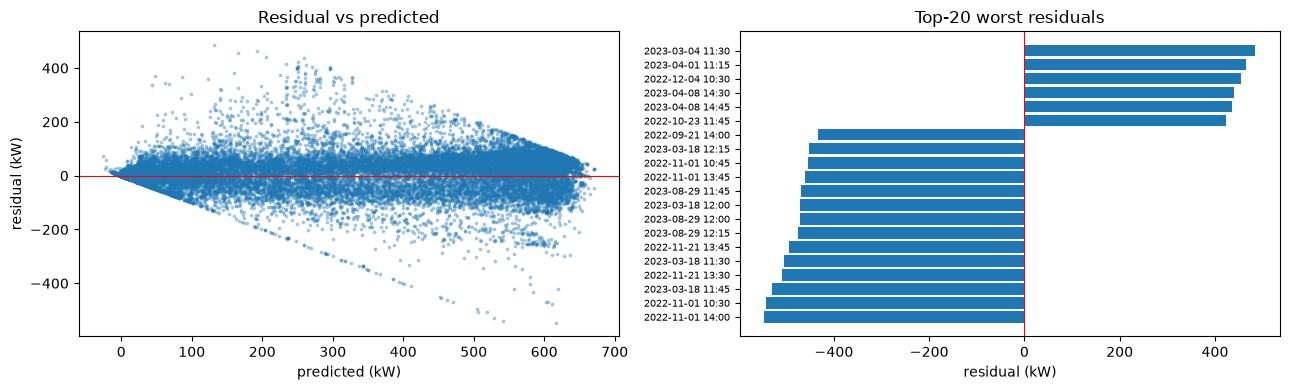

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].scatter(worst["predicted"], worst["residual"], s=3, alpha=0.3)
ax[0].axhline(0, color="red", lw=0.8); ax[0].set_xlabel("predicted (kW)"); ax[0].set_ylabel("residual (kW)"); ax[0].set_title("Residual vs predicted")

top20_plot = top20.sort_values("residual")
ax[1].barh(range(len(top20_plot)), top20_plot["residual"])
ax[1].set_yticks(range(len(top20_plot))); ax[1].set_yticklabels(top20_plot["measured_on"].dt.strftime("%Y-%m-%d %H:%M"), fontsize=7)
ax[1].axvline(0, color="red", lw=0.8); ax[1].set_xlabel("residual (kW)"); ax[1].set_title("Top-20 worst residuals")

plt.tight_layout(); plt.show()

In [5]:
# Investigate the two suspicious POA=6.5 rows (midday, dead sensor or merge bug?)
raw_irr = raw["irradiance"]
raw_meter = raw["meter"]

for ts in ["2022-11-21 13:45", "2022-10-23 11:45"]:
    t = pd.Timestamp(ts)
    print(f"\n=== {ts} ===")
    print("Raw irradiance (5min):")
    print(raw_irr[raw_irr["measured_on"].between(t - pd.Timedelta("15min"), t)][["measured_on", IRRADIANCE_COL]])
    print("Raw meter (15min):")
    print(raw_meter[raw_meter["measured_on"] == t][["measured_on", TARGET_COL]])


=== 2022-11-21 13:45 ===
Raw irradiance (5min):
               measured_on  poa_irradiance_o_149574
448656 2022-11-21 13:30:00                    578.8
Raw meter (15min):
               measured_on  meter_revenue_grade_ac_output_meter_149578
206234 2022-11-21 13:45:00                                      9.7664

=== 2022-10-23 11:45 ===
Raw irradiance (5min):
Empty DataFrame
Columns: [measured_on, poa_irradiance_o_149574]
Index: []
Raw meter (15min):
               measured_on  meter_revenue_grade_ac_output_meter_149578
203446 2022-10-23 11:45:00                                       675.2


## What the worst residuals tell us (corrected)

1. Type A (over-predicted at bright sky, actual ≈ 0):
   REAL outages — these are exactly what SolarOps exists to flag.

2. Type B (both POA=6.566667 at midday):
   NOT sensor glitches. These are **imputation artifacts** — the imputer
   filled missing POA with the training median (6.566667), and LGBM trusted
   the fake value + hour feature to predict ~500 kW when actual was ~0-675.
   → Model has no way to know a value is imputed.

## Action
Add `<feature>_is_missing` binary flags before imputation, retrain, compare.